In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import pandas as pd

df = pd.read_csv(
    "data.csv",
    sep=";",
    encoding="utf-8-sig",   # -sig supprime le BOM proprement
    decimal=",",
    low_memory=False
)

print(df.shape)   # (4271, 256)
print(df.dtypes.value_counts())

(4271, 256)
float64    245
str          8
int64        3
Name: count, dtype: int64


In [22]:
print(df.columns)

Index(['Patient_ID', 'Chip_Type', 'Age', 'Gender', 'Blood_Month_sample',
       'French_Residence_Department', 'French_Region', 'Rural_or_urban_area',
       'Sensitization', 'Treatment_of_rhinitis',
       ...
       'Man_i', 'Mel_g', 'Mes_a_1_RUO', 'Mor_r', 'Mus_a', 'Myt_e',
       'Ole_e_7_RUO', 'Ori_v', 'Ory_c_1', 'Ory_c_2'],
      dtype='str', length=256)


In [29]:
chip_dict={}
for chip in df.Chip_Type:
    chip_dict[chip]=df[df.Chip_Type == chip]

In [32]:
print(chip_dict["ISAC_V1"].head())

  Patient_ID Chip_Type   Age  Gender  Blood_Month_sample  \
0    FHB0001   ISAC_V1  21.0     1.0                11.0   
1    FHB0002   ISAC_V1  45.0     0.0                12.0   
2    FHB0003   ISAC_V1  18.0     1.0                 1.0   
3    FHB0004   ISAC_V1  19.0     0.0                 1.0   
4    FHB0005   ISAC_V1  28.0     0.0                 1.0   

  French_Residence_Department French_Region  Rural_or_urban_area  \
0                       deptY       regionB                    9   
1                       deptY       regionB                    9   
2                       deptY       regionB                    9   
3                       deptY       regionB                    9   
4                       deptY       regionB                    9   

   Sensitization  Treatment_of_rhinitis  ... Man_i Mel_g  Mes_a_1_RUO Mor_r  \
0              1                    9.0  ...   NaN   NaN          NaN   NaN   
1              1                    9.0  ...   NaN   NaN          NaN   

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def plot_matrix(df):
    # 1. Sélection des colonnes numériques
    df_num = df.select_dtypes(include=np.number)

    # 2. Matrice de corrélation
    corr = df_num.corr(method="pearson")      # ou "spearman" (cf. remarques)

    # 3. Heatmap hiérarchisée (clustering des colonnes pour faire émerger les familles)
    plt.figure(figsize=(14, 12))
    corr_clean = corr.dropna(axis=0, how="any").dropna(axis=1, how="any")

    # 2. Clustermap sur la matrice propre
    sns.clustermap(
        corr_clean,
        method="average",
        cmap="coolwarm",
        vmin=-1, vmax=1,
        figsize=(15, 15)
    )
    plt.show()

ValueError: The number of observations cannot be determined on an empty distance matrix.

<Figure size 1400x1200 with 0 Axes>

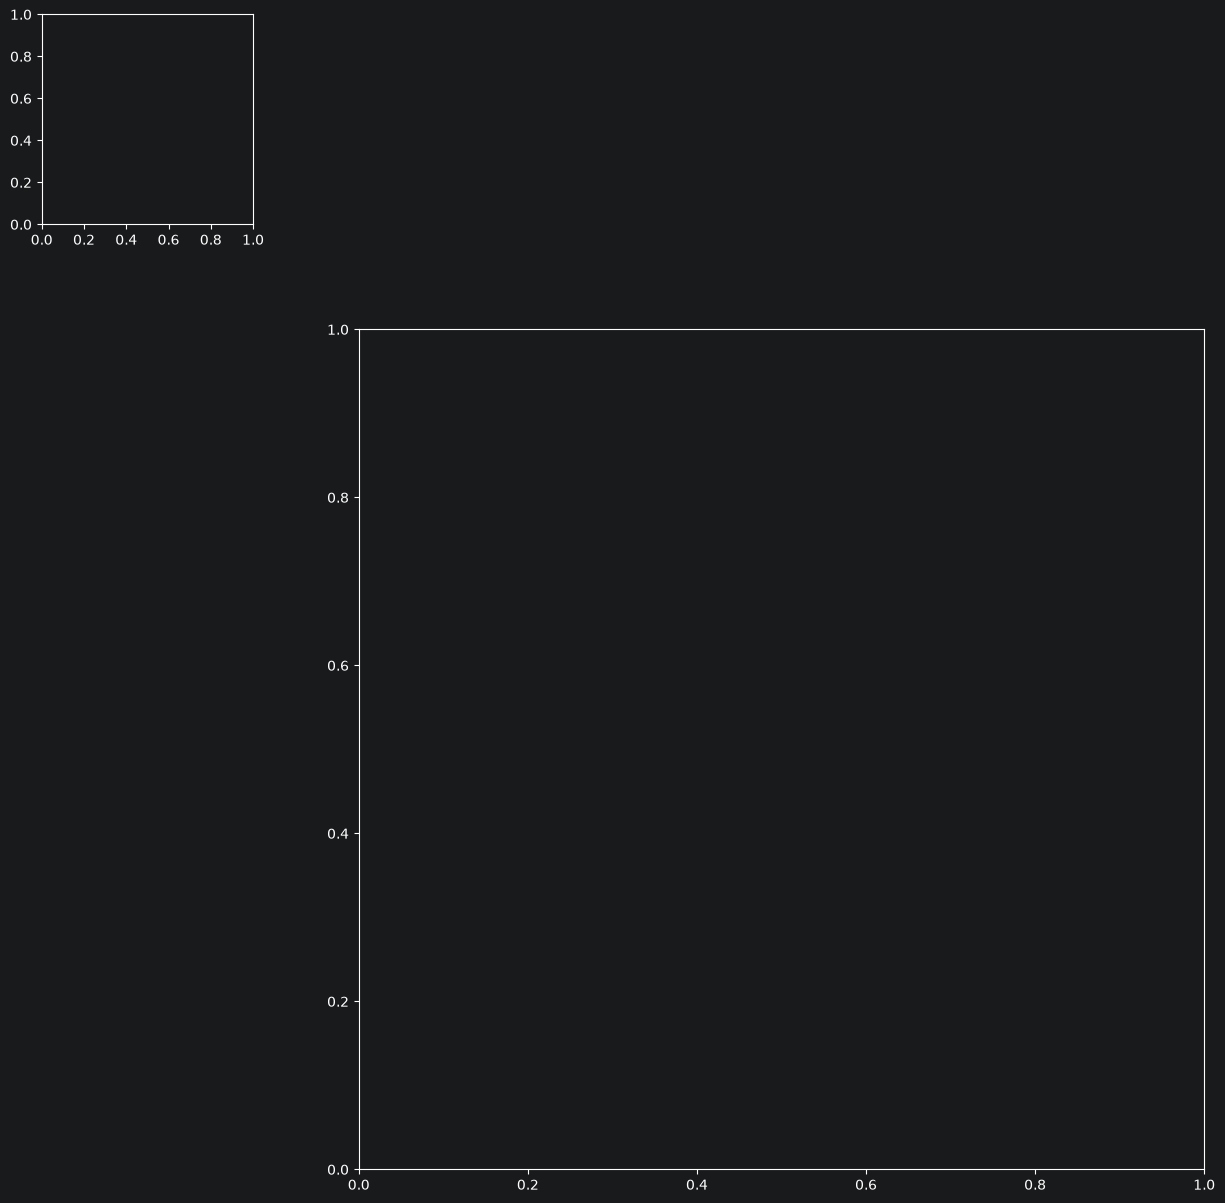

In [34]:
for k in chip_dict.keys():
    plot_matrix(chip_dict[k])